<a href="https://colab.research.google.com/github/bryanxq21/actividad-4/blob/main/Actividad_4_Emisiones_CO2_Colombia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 4 – Análisis de emisiones de CO₂ en Colombia

**Fuente:** Our World in Data (OWID)  
**Tema:** Evolución de las emisiones anuales de dióxido de carbono (CO₂) en Colombia.  
**Periodo de análisis:** 1990 hasta el último año disponible en la base de datos.

## Objetivo
Descargar y preparar datos abiertos de Our World in Data, explorar la evolución de las emisiones de CO₂ de Colombia mediante visualizaciones y construir un modelo de regresión lineal para estudiar la tendencia temporal y realizar proyecciones exploratorias.

**Nota metodológica:** la variable corresponde a emisiones territoriales anuales de CO₂ procedentes de combustibles fósiles y de la industria, según la definición de la serie seleccionada. No equivale a la huella de carbono del consumo ni incluye necesariamente todos los gases de efecto invernadero.

## 1. Librerías

Si alguna librería no está instalada, descomenta la línea `pip install` y ejecútala.

In [3]:
# Si es necesario, instala las librerías:
# %pip install pandas numpy matplotlib seaborn scikit-learn requests

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descarga de los datos

Se utiliza el archivo CSV público de Our World in Data. El código identifica automáticamente la columna de emisiones para evitar depender de una etiqueta exacta que pueda cambiar.

In [4]:
url = "https://ourworldindata.org/grapher/annual-co2-emissions-per-country.csv"

try:
    datos_originales = pd.read_csv(url)
    print("Datos descargados correctamente desde Our World in Data.")
except Exception as error:
    raise RuntimeError(
        "No fue posible descargar los datos. Verifica tu conexión a internet "
        "e inténtalo nuevamente. Detalle: " + str(error)
    )

print("Dimensiones de la base:", datos_originales.shape)
display(datos_originales.head())
print("\\nColumnas disponibles:")
print(datos_originales.columns.tolist())

Datos descargados correctamente desde Our World in Data.
Dimensiones de la base: (30219, 4)


,Entity,Code,Year,Annual COâ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0



Columnas disponibles:
['Entity', 'Code', 'Year', 'Annual COâ\x82\x82 emissions']


## 3. Limpieza y preparación

Se selecciona Colombia, se conservan los registros desde 1990, se convierten las variables a formato numérico y se eliminan registros sin año o sin dato de emisiones.

In [5]:
# Identificar automáticamente la columna de emisiones
columnas_base = {"Entity", "Code", "Year"}
columnas_emisiones = [c for c in datos_originales.columns if c not in columnas_base]

if not columnas_emisiones:
    raise ValueError("No se encontró una columna de emisiones en el archivo.")

columna_emisiones = columnas_emisiones[0]
print("Columna de emisiones utilizada:", columna_emisiones)

# Seleccionar Colombia
colombia = datos_originales.loc[
    datos_originales["Entity"].astype(str).str.strip().str.lower() == "colombia",
    ["Entity", "Year", columna_emisiones]
].copy()

# Estandarizar nombres
colombia = colombia.rename(columns={
    "Entity": "Pais",
    "Year": "Anio",
    columna_emisiones: "Emisiones_CO2_toneladas"
})

# Conversión de tipos y limpieza
colombia["Anio"] = pd.to_numeric(colombia["Anio"], errors="coerce")
colombia["Emisiones_CO2_toneladas"] = pd.to_numeric(
    colombia["Emisiones_CO2_toneladas"], errors="coerce"
)

colombia = colombia.dropna(subset=["Anio", "Emisiones_CO2_toneladas"])
colombia = colombia[colombia["Anio"] >= 1990]
colombia = colombia[colombia["Emisiones_CO2_toneladas"] >= 0]
colombia["Anio"] = colombia["Anio"].astype(int)

# Ordenar y eliminar posibles duplicados
colombia = (
    colombia.sort_values("Anio")
    .drop_duplicates(subset=["Anio"], keep="last")
    .reset_index(drop=True)
)

if len(colombia) < 10:
    raise ValueError("Hay muy pocos registros para realizar un análisis y entrenar el modelo.")

print("Registros después de la limpieza:", len(colombia))
print("Periodo:", colombia["Anio"].min(), "-", colombia["Anio"].max())
print("Valores nulos después de limpiar:", int(colombia.isna().sum().sum()))
display(colombia.head())
display(colombia.tail())

Columna de emisiones utilizada: Annual COâ emissions
Registros después de la limpieza: 36
Periodo: 1990 - 2025
Valores nulos después de limpiar: 0


,Pais,Anio,Emisiones_CO2_toneladas
0,Colombia,1990,56061840.0
1,Colombia,1991,55861576.0
2,Colombia,1992,60461310.0
3,Colombia,1993,62373510.0
4,Colombia,1994,65772444.0


,Pais,Anio,Emisiones_CO2_toneladas
31,Colombia,2021,103414850.0
32,Colombia,2022,101543710.0
33,Colombia,2023,105349000.0
34,Colombia,2024,106288370.0
35,Colombia,2025,96066940.0


## 4. Análisis exploratorio

Se calculan medidas estadísticas para conocer el comportamiento general de las emisiones durante el periodo seleccionado.

In [6]:
estadisticas = colombia["Emisiones_CO2_toneladas"].describe().to_frame("Valor")
display(estadisticas)

print(f"Emisiones mínimas: {colombia['Emisiones_CO2_toneladas'].min():,.0f} toneladas")
print(f"Emisiones máximas: {colombia['Emisiones_CO2_toneladas'].max():,.0f} toneladas")
print(f"Promedio del periodo: {colombia['Emisiones_CO2_toneladas'].mean():,.0f} toneladas")

,Valor
count,3.600000e+01
mean,7.559794e+07
std,1.698853e+07
min,5.586158e+07
25%,6.165927e+07
50%,6.868351e+07
75%,9.309061e+07
max,1.062884e+08


Emisiones mínimas: 55,861,576 toneladas
Emisiones máximas: 106,288,370 toneladas
Promedio del periodo: 75,597,943 toneladas


## 5. Visualización de la evolución de Colombia

El primer gráfico muestra la serie histórica. El segundo presenta el cambio porcentual anual, que ayuda a observar aumentos y disminuciones de un año a otro.

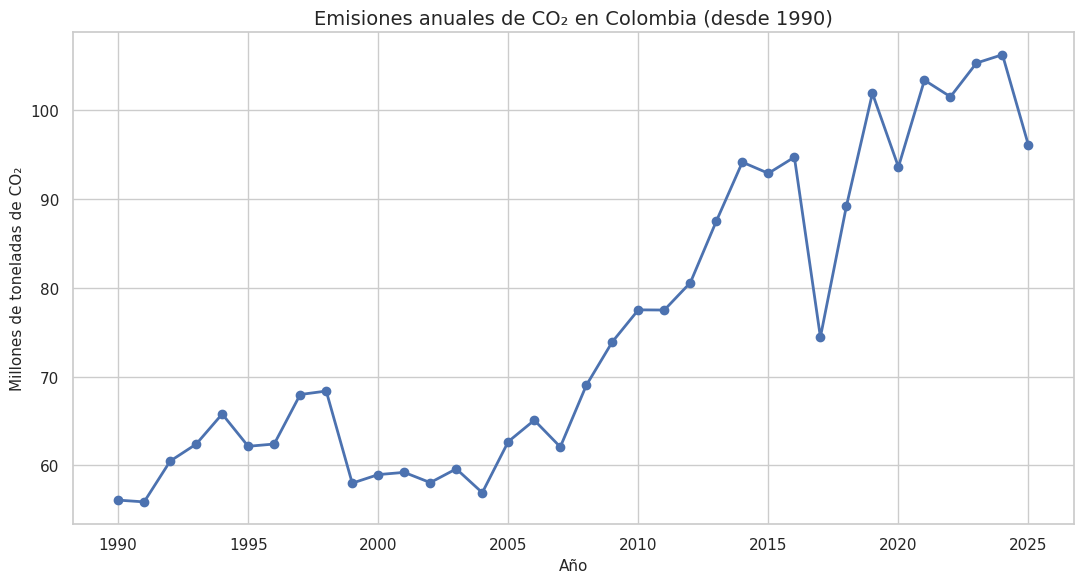

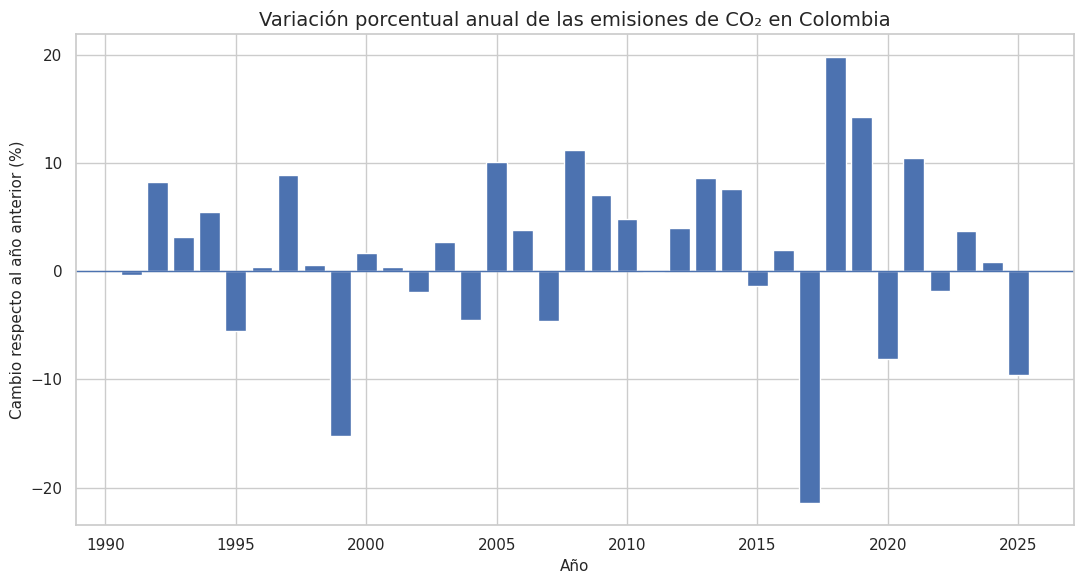

In [7]:
plt.figure()
plt.plot(
    colombia["Anio"],
    colombia["Emisiones_CO2_toneladas"] / 1_000_000,
    marker="o",
    linewidth=2
)
plt.title("Emisiones anuales de CO₂ en Colombia (desde 1990)")
plt.xlabel("Año")
plt.ylabel("Millones de toneladas de CO₂")
plt.tight_layout()
plt.show()

colombia["Variacion_porcentual"] = (
    colombia["Emisiones_CO2_toneladas"].pct_change() * 100
)

plt.figure()
plt.bar(
    colombia["Anio"],
    colombia["Variacion_porcentual"],
    width=0.8
)
plt.axhline(0, linewidth=1)
plt.title("Variación porcentual anual de las emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Cambio respecto al año anterior (%)")
plt.tight_layout()
plt.show()

## 6. Comparación entre países en el último año disponible

Esta visualización permite ubicar a Colombia frente a otros países. Se utiliza el último año que tenga datos para Colombia y se comparan los diez países con mayores emisiones disponibles en ese mismo año.

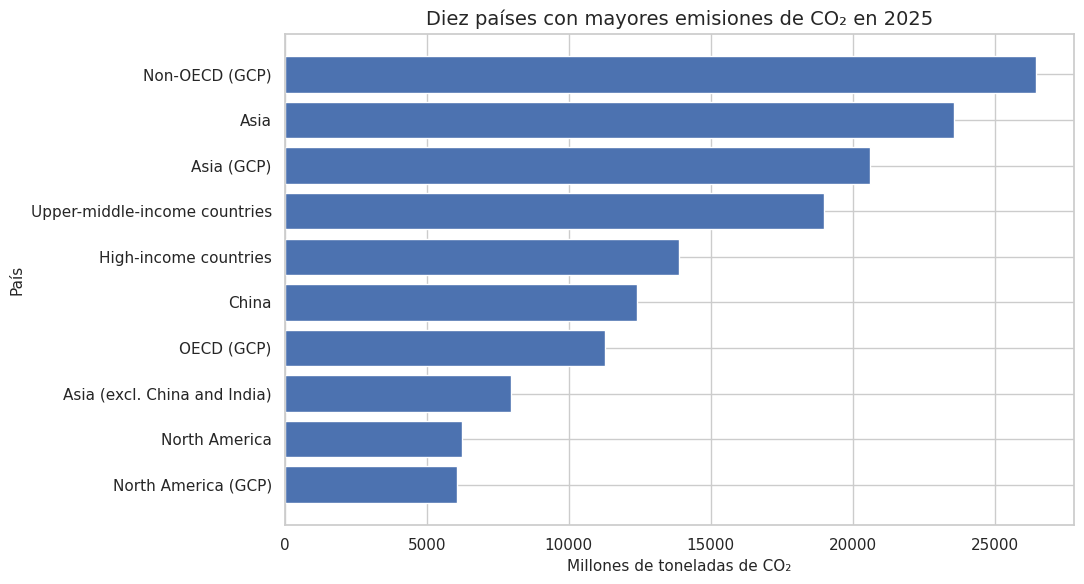

Colombia en 2025: 96,066,940 toneladas de CO₂.


In [8]:
ultimo_anio = int(colombia["Anio"].max())

comparacion = datos_originales.loc[
    datos_originales["Year"] == ultimo_anio,
    ["Entity", columna_emisiones]
].copy()

comparacion[columna_emisiones] = pd.to_numeric(
    comparacion[columna_emisiones], errors="coerce"
)
comparacion = comparacion.dropna()
comparacion = comparacion[comparacion["Entity"] != "World"]
top_10 = comparacion.nlargest(10, columna_emisiones).sort_values(columna_emisiones)

plt.figure()
plt.barh(
    top_10["Entity"],
    top_10[columna_emisiones] / 1_000_000
)
plt.title(f"Diez países con mayores emisiones de CO₂ en {ultimo_anio}")
plt.xlabel("Millones de toneladas de CO₂")
plt.ylabel("País")
plt.tight_layout()
plt.show()

valor_colombia = colombia.loc[
    colombia["Anio"] == ultimo_anio, "Emisiones_CO2_toneladas"
].iloc[0]
print(f"Colombia en {ultimo_anio}: {valor_colombia:,.0f} toneladas de CO₂.")

## 7. Construcción del modelo de regresión lineal

La regresión lineal utiliza el año como variable independiente y las emisiones como variable dependiente. Para evaluar el modelo, se separan los datos cronológicamente: los años más antiguos se usan para entrenar y los más recientes para probar. Así se evita mezclar años futuros dentro del entrenamiento.

In [9]:
X = colombia[["Anio"]]
y = colombia["Emisiones_CO2_toneladas"]

# Separación cronológica: 80 % inicial para entrenamiento y 20 % final para prueba
punto_corte = int(len(colombia) * 0.8)
X_train, X_test = X.iloc[:punto_corte], X.iloc[punto_corte:]
y_train, y_test = y.iloc[:punto_corte], y.iloc[punto_corte:]

modelo = LinearRegression()
modelo.fit(X_train, y_train)

predicciones = modelo.predict(X_test)

print("Modelo entrenado correctamente.")
print(f"Pendiente: {modelo.coef_[0]:,.2f} toneladas por año")
print(f"Intercepto: {modelo.intercept_:,.2f}")

Modelo entrenado correctamente.
Pendiente: 1,144,660.92 toneladas por año
Intercepto: -2,224,610,830.85


## 8. Evaluación del modelo

Se utilizan tres métricas: MAE y RMSE (error en toneladas) y R² (proporción de variabilidad explicada por el modelo). Un R² bajo o negativo indica que la recta no representa bien los datos de prueba.

In [10]:
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

metricas = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Resultado": [mae, rmse, r2]
})
display(metricas)

print(f"MAE: {mae:,.0f} toneladas")
print(f"RMSE: {rmse:,.0f} toneladas")
print(f"R²: {r2:.4f}")

,Métrica,Resultado
0,MAE,1.035890e+07
1,RMSE,1.147280e+07
2,R²,-3.090321e+00


MAE: 10,358,904 toneladas
RMSE: 11,472,803 toneladas
R²: -3.0903


## 9. Visualización de valores reales y predichos

Se compara la serie real con la recta ajustada y se muestran los valores estimados para el conjunto de prueba.

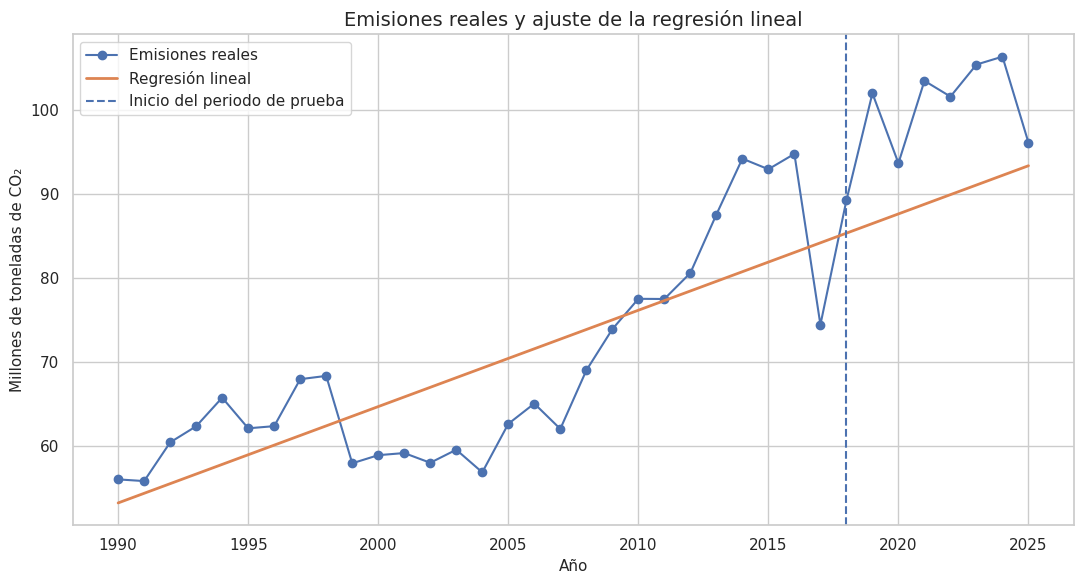

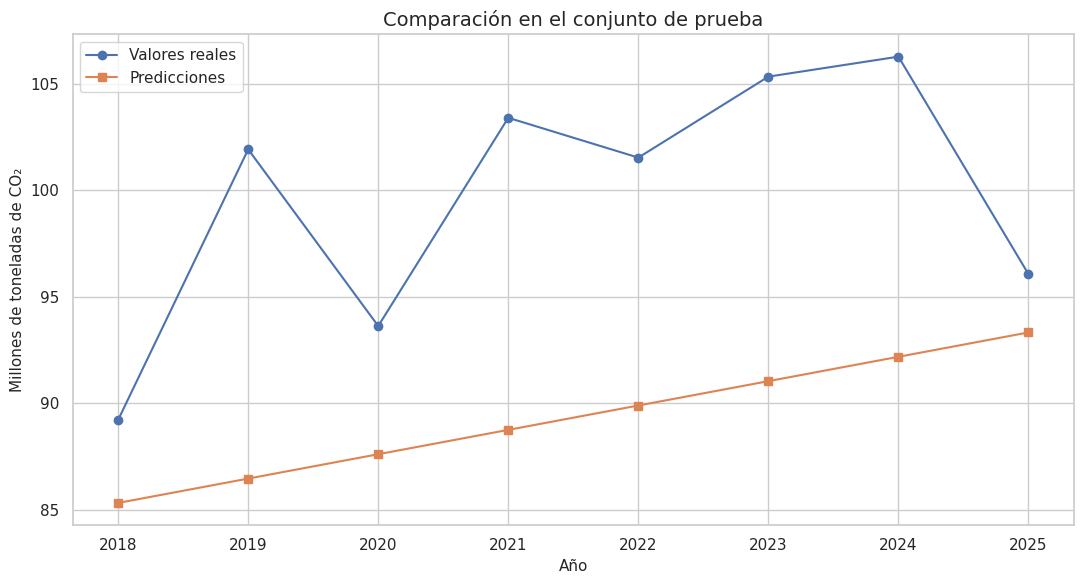

In [11]:
# Predicción sobre todos los años observados, solo para visualizar el ajuste
ajuste_total = modelo.predict(X)

plt.figure()
plt.plot(
    colombia["Anio"],
    colombia["Emisiones_CO2_toneladas"] / 1_000_000,
    label="Emisiones reales",
    marker="o"
)
plt.plot(
    colombia["Anio"],
    ajuste_total / 1_000_000,
    label="Regresión lineal",
    linewidth=2
)
plt.axvline(
    X_test["Anio"].min(),
    linestyle="--",
    label="Inicio del periodo de prueba"
)
plt.title("Emisiones reales y ajuste de la regresión lineal")
plt.xlabel("Año")
plt.ylabel("Millones de toneladas de CO₂")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(X_test["Anio"], y_test / 1_000_000, marker="o", label="Valores reales")
plt.plot(X_test["Anio"], predicciones / 1_000_000, marker="s", label="Predicciones")
plt.title("Comparación en el conjunto de prueba")
plt.xlabel("Año")
plt.ylabel("Millones de toneladas de CO₂")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Proyección exploratoria para 2030 y 2035

Se utiliza la recta entrenada para estimar las emisiones en 2030 y 2035. Estas cifras son proyecciones matemáticas basadas en la tendencia histórica, no predicciones definitivas: no incorporan cambios futuros en políticas públicas, tecnología, economía, población ni matriz energética.

,Anio,Emisiones_estimadas_toneladas,Emisiones_estimadas_millones_toneladas
0,2030,9.905083e+07,99.05
1,2035,1.047741e+08,104.77


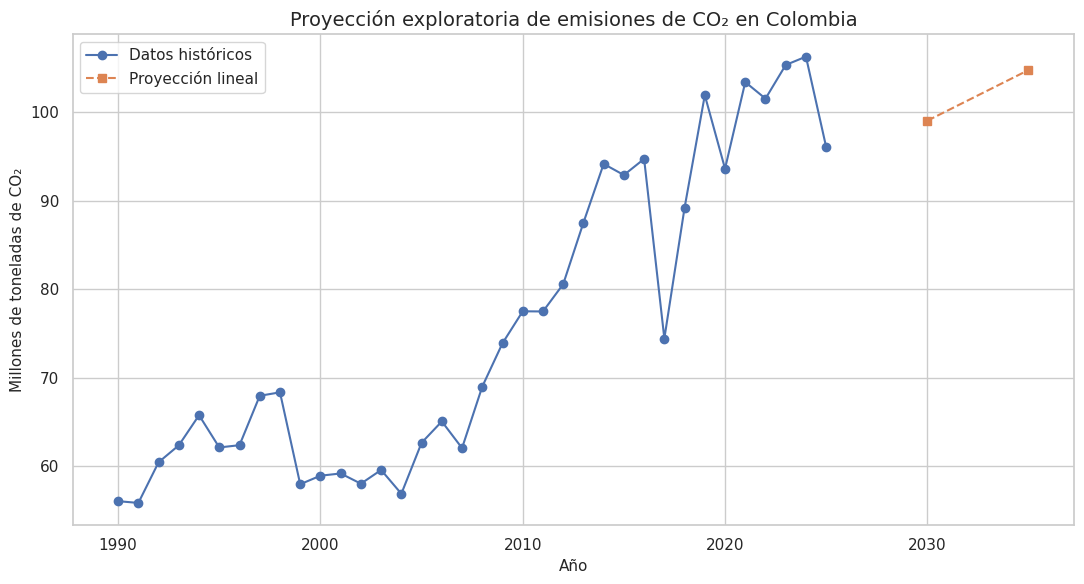

In [12]:
anios_futuros = pd.DataFrame({"Anio": [2030, 2035]})
proyecciones = modelo.predict(anios_futuros)

tabla_proyecciones = pd.DataFrame({
    "Anio": anios_futuros["Anio"],
    "Emisiones_estimadas_toneladas": proyecciones,
    "Emisiones_estimadas_millones_toneladas": proyecciones / 1_000_000
})
display(tabla_proyecciones.round(2))

plt.figure()
plt.plot(
    colombia["Anio"],
    colombia["Emisiones_CO2_toneladas"] / 1_000_000,
    marker="o",
    label="Datos históricos"
)
plt.plot(
    anios_futuros["Anio"],
    proyecciones / 1_000_000,
    marker="s",
    linestyle="--",
    label="Proyección lineal"
)
plt.title("Proyección exploratoria de emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Millones de toneladas de CO₂")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Interpretación automática de resultados

El texto siguiente resume la dirección de la tendencia y las métricas calculadas. Debe leerse junto con los gráficos y teniendo en cuenta las limitaciones del modelo.

In [13]:
pendiente = modelo.coef_[0]

if pendiente > 0:
    tendencia = "creciente"
elif pendiente < 0:
    tendencia = "decreciente"
else:
    tendencia = "estable"

primera_emision = colombia.iloc[0]["Emisiones_CO2_toneladas"]
ultima_emision = colombia.iloc[-1]["Emisiones_CO2_toneladas"]
cambio_total = ((ultima_emision - primera_emision) / primera_emision) * 100 if primera_emision != 0 else np.nan

print(f"Entre {int(colombia['Anio'].min())} y {int(colombia['Anio'].max())}, "
      f"las emisiones registradas pasaron de {primera_emision:,.0f} a "
      f"{ultima_emision:,.0f} toneladas.")
print(f"El cambio porcentual entre el primer y el último año del periodo fue de {cambio_total:.2f}%.")
print(f"La pendiente del modelo indica una tendencia lineal {tendencia}, "
      f"de aproximadamente {pendiente:,.0f} toneladas por año.")
print(f"El modelo obtuvo un MAE de {mae:,.0f} toneladas, un RMSE de {rmse:,.0f} toneladas "
      f"y un R² de {r2:.4f} en el conjunto de prueba.")

if r2 >= 0.7:
    print("Interpretación: el modelo explica una parte importante de la variación observada en el periodo de prueba.")
elif r2 >= 0.3:
    print("Interpretación: el modelo tiene capacidad explicativa limitada; hay variaciones que la tendencia lineal no captura.")
else:
    print("Interpretación: el ajuste lineal es débil para el periodo de prueba. Las emisiones presentan cambios que una recta no representa adecuadamente.")

print("\\nConclusión: la regresión lineal sirve como primera aproximación para describir una tendencia, "
      "pero no demuestra causalidad ni debe considerarse un pronóstico definitivo. "
      "Las emisiones dependen de factores económicos, energéticos, tecnológicos y de política ambiental.")

Entre 1990 y 2025, las emisiones registradas pasaron de 56,061,840 a 96,066,940 toneladas.
El cambio porcentual entre el primer y el último año del periodo fue de 71.36%.
La pendiente del modelo indica una tendencia lineal creciente, de aproximadamente 1,144,661 toneladas por año.
El modelo obtuvo un MAE de 10,358,904 toneladas, un RMSE de 11,472,803 toneladas y un R² de -3.0903 en el conjunto de prueba.
Interpretación: el ajuste lineal es débil para el periodo de prueba. Las emisiones presentan cambios que una recta no representa adecuadamente.
\nConclusión: la regresión lineal sirve como primera aproximación para describir una tendencia, pero no demuestra causalidad ni debe considerarse un pronóstico definitivo. Las emisiones dependen de factores económicos, energéticos, tecnológicos y de política ambiental.


## 12. Exportación de la base limpia

Se guarda la tabla utilizada en el análisis para facilitar su consulta y reutilización.

In [14]:
archivo_salida = "emisiones_co2_colombia_limpio.csv"
colombia.to_csv(archivo_salida, index=False, encoding="utf-8-sig")
print(f"Archivo exportado: {archivo_salida}")

Archivo exportado: emisiones_co2_colombia_limpio.csv


## 13. Conclusiones

El análisis permite estudiar cómo han cambiado las emisiones anuales de CO₂ de Colombia desde 1990 y observar sus variaciones a través del tiempo. Las visualizaciones ayudan a identificar periodos de crecimiento o disminución, mientras que la comparación internacional ofrece contexto sobre la distribución global de las emisiones.

La regresión lineal resume la tendencia temporal mediante una línea recta y permite generar estimaciones exploratorias para 2030 y 2035. Sin embargo, su capacidad predictiva depende de las métricas obtenidas en los datos de prueba. El comportamiento real de las emisiones puede cambiar por transformaciones económicas, políticas ambientales, eficiencia energética y uso de tecnologías más limpias.

Por tanto, los resultados deben interpretarse como un análisis descriptivo y una aproximación estadística, no como una predicción segura del futuro. La información de Our World in Data permite respaldar el análisis con datos abiertos y comparables.

## Referencias

- Our World in Data. (s. f.). *CO₂ emissions*. https://ourworldindata.org/co2-emissions
- Our World in Data. (s. f.). *Annual CO₂ emissions*. https://ourworldindata.org/grapher/annual-co2-emissions-per-country